<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s):
* Reyna Der Boghosian

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
import pickle
import os

In [3]:
if not os.path.exists('spa-eng'):
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip")

with open("./spa-eng/spa.txt") as f:
    lines = f.read().split("\n")[:-1]

In [4]:
MAX_NUM_SENTENCES = 30000 # cambiamos el parametro a 30000

np.random.seed(40)
np.random.shuffle(lines)

In [5]:
input_sentences, output_sentences, output_sentences_inputs = [], [], []

for i, line in enumerate(lines):
    if i >= MAX_NUM_SENTENCES:
        break
    if '\t' not in line:
        continue
    input_sentence, output = line.rstrip().split('\t')[:2]
    output_sentences.append(output + ' <eos>')
    output_sentences_inputs.append('<sos> ' + output)
    input_sentences.append(input_sentence)

print(f"Oraciones cargadas: {len(input_sentences)}")

Oraciones cargadas: 30000


In [6]:
print(input_sentences[0])
print(output_sentences[0])
print(output_sentences_inputs[0])

Somebody stole my car.
Alguien robó mi auto. <eos>
<sos> Alguien robó mi auto.


In [7]:
MAX_VOCAB_SIZE = 8000

input_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
input_tokenizer.fit_on_texts(input_sentences)
input_integer_seq = input_tokenizer.texts_to_sequences(input_sentences)
word2idx_inputs = input_tokenizer.word_index

#Solo se tomarán en cuenta las 8000 palabras más frecuentes y se eliminan signos de puntuación
output_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters='!"#$%&()*+,-./:;=¿?@[\\]^_`{|}~\t\n'
)

output_tokenizer.fit_on_texts(["<sos>", "<eos>"] + output_sentences)
output_integer_seq = output_tokenizer.texts_to_sequences(output_sentences)
output_input_integer_seq = output_tokenizer.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = output_tokenizer.word_index

num_words_output = min(len(word2idx_outputs) + 1, MAX_VOCAB_SIZE)

max_input_len = 30 # cambiamos el valor de 20 a 30
max_out_len   = 32 # cambiamos el valor de 22 a 32

print(f"Vocabulario EN: {len(word2idx_inputs)} | ES: {len(word2idx_outputs)}")
print(f"max_input_len={max_input_len}  max_out_len={max_out_len}")

Vocabulario EN: 8072 | ES: 13954
max_input_len=30  max_out_len=32


In [8]:
encoder_input_sequences  = pad_sequences(input_integer_seq,        maxlen=max_input_len)
decoder_input_sequences  = pad_sequences(output_input_integer_seq, maxlen=max_out_len, padding='post')
decoder_output_sequences = pad_sequences(output_integer_seq,       maxlen=max_out_len, padding='post')

In [9]:
def make_dataset(enc_seqs, dec_in_seqs, dec_out_seqs, batch_size, num_classes):

    n = len(enc_seqs)

    def generator():
        for i in range(n):
            yield (
                enc_seqs[i].astype(np.int32),
                dec_in_seqs[i].astype(np.int32),
                dec_out_seqs[i].astype(np.int32),
            )

    def encode_one_hot(enc, dec_in, dec_out):
        y = tf.one_hot(dec_out, depth=num_classes)          # shape (max_out_len, num_classes)
        return (enc, dec_in), y

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(max_input_len,), dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,),   dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,),   dtype=tf.int32),
        )
    )
    ds = ds.map(encode_one_hot, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

In [10]:
BATCH_SIZE = 64
val_split  = 0.15
split_idx  = int(len(encoder_input_sequences) * (1 - val_split))

train_ds = make_dataset(
    encoder_input_sequences[:split_idx],
    decoder_input_sequences[:split_idx],
    decoder_output_sequences[:split_idx],
    BATCH_SIZE, num_words_output
)
val_ds = make_dataset(
    encoder_input_sequences[split_idx:],
    decoder_input_sequences[split_idx:],
    decoder_output_sequences[split_idx:],
    BATCH_SIZE, num_words_output
)

In [11]:
def _is_valid_pickle(path):
    try:
        with open(path, 'rb') as f:
            head = f.read(20)
        return b'<html' not in head.lower() and b'<!doctype' not in head.lower()
    except Exception:
        return False

_PKL_PATH = 'gloveembedding.pkl'
_FILE_ID  = '1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94'

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl desde Google Drive...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown
        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception:
        os.system(f"curl -L -o {_PKL_PATH} "
                  f"'https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t'")
    if not _is_valid_pickle(_PKL_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

Descargando gloveembedding.pkl desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94
From (redirected): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94&confirm=t&uuid=d494f7cf-2389-4e0f-91a5-a7c8dbaf8fe9
To: /content/gloveembedding.pkl
100%|██████████| 525M/525M [00:01<00:00, 303MB/s]

Descarga completada.


In [12]:
def load_glove_embeddings(pkl_path):
    """Carga el pickle de GloVe y devuelve (word2idx, matrix_fn)."""
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz  = os.path.getsize(pkl_path)
    with open(pkl_path, 'rb') as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array  = np.arange(embeddings.shape[0])
    word2idx   = dict(zip(embeddings['word'], idx_array))
    return embeddings, word2idx

In [13]:
def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]['embedding'] if i != -1 else np.zeros(n_features)

In [14]:
def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove,
                            nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix

In [15]:
EMBED_DIM = 50
nb_words  = min(MAX_VOCAB_SIZE, len(word2idx_inputs))

glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
embedding_matrix = build_embedding_matrix(
    word2idx_inputs, glove_embeddings, glove_word2idx, nb_words, EMBED_DIM
)
print(f"Embeddings nulos: {np.sum(np.sum(embedding_matrix**2, axis=1) == 0)}")

Embeddings nulos: 398


#Modelo Seq2Seq

In [20]:
n_units = 256

In [16]:
def build_encoder(nb_words, embed_dim, embedding_matrix, max_input_len, n_units):

    enc_inputs   = Input(shape=(max_input_len,), name='encoder_inputs')

    enc_emb_layer = Embedding(
        input_dim=nb_words,
        output_dim=embed_dim,
        input_length=max_input_len,
        weights=[embedding_matrix],
        trainable=False,
        name='encoder_embedding'
    )
    enc_emb = Dropout(0.3, name='encoder_dropout')(enc_emb_layer(enc_inputs))

    enc_lstm_layer = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm_layer(enc_emb)

    return enc_inputs, [state_h, state_c], enc_emb_layer, enc_lstm_layer

In [17]:
def build_decoder(num_words_output, max_out_len, n_units, encoder_states):

    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')

    dec_emb_layer = Embedding(
        input_dim=num_words_output,
        output_dim=n_units,
        input_length=max_out_len,
        name='decoder_embedding'
    )
    dec_emb = Dropout(0.3, name='decoder_dropout')(dec_emb_layer(dec_inputs))

    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True,
                          name='decoder_lstm')
    dec_out, _, _  = dec_lstm_layer(dec_emb, initial_state=encoder_states)

    dec_dense_layer = Dense(num_words_output, activation='softmax', name='decoder_dense')
    dec_out         = dec_dense_layer(dec_out)

    return dec_inputs, dec_out, dec_emb_layer, dec_lstm_layer, dec_dense_layer

In [21]:
enc_inputs, enc_states, enc_emb_layer, enc_lstm_layer = build_encoder(
    nb_words, EMBED_DIM, embedding_matrix, max_input_len, n_units
)
dec_inputs, dec_outputs, dec_emb_layer, dec_lstm_layer, dec_dense_layer = build_decoder(
    num_words_output, max_out_len, n_units, enc_states
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
# se ajusta esta parte
EMBED_DIM = 50

# +1 porque los índices de las palabras comienzan en 1
# y el índice 0 se reserva para el padding.
nb_words = min(MAX_VOCAB_SIZE, len(word2idx_inputs) + 1)

glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)

embedding_matrix = build_embedding_matrix(
    word2idx_inputs,
    glove_embeddings,
    glove_word2idx,
    nb_words,
    EMBED_DIM
)

print("Dimensiones de la matriz:", embedding_matrix.shape)
print(
    "Embeddings nulos:",
    np.sum(np.sum(embedding_matrix**2, axis=1) == 0)
)

Dimensiones de la matriz: (8000, 50)
Embeddings nulos: 398


In [23]:
from google.colab import drive
drive.mount("/content/drive")
import os
import json
import matplotlib.pyplot as plt

DIR_RESULTADOS = "/content/drive/MyDrive/PLN/desafio_4"
os.makedirs(DIR_RESULTADOS, exist_ok=True)

Mounted at /content/drive


In [23]:
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

CONFIGURACIONES = [128, 256, 384]

modelos = {}
historiales = {}
artefactos = {}

for n_units in CONFIGURACIONES:
    print(f"\n{'=' * 50}")
    print(f"Entrenando traductor con {n_units} unidades LSTM")
    print(f"{'=' * 50}")

    # Encoder
    enc_inputs, enc_states, enc_emb_layer, enc_lstm_layer = (
        build_encoder(
            nb_words,
            EMBED_DIM,
            embedding_matrix,
            max_input_len,
            n_units
        )
    )

    # Decoder
    (
        dec_inputs,
        dec_outputs,
        dec_emb_layer,
        dec_lstm_layer,
        dec_dense_layer
    ) = build_decoder(
        num_words_output,
        max_out_len,
        n_units,
        enc_states
    )

    model = Model([enc_inputs, dec_inputs], dec_outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        loss="categorical_crossentropy",
        weighted_metrics=["accuracy"]
    )

    model.summary()

    dir_config = os.path.join(
        DIR_RESULTADOS, f"lstm_{n_units}"
    )
    os.makedirs(dir_config, exist_ok=True)

    callbacks = [
        ModelCheckpoint(
            os.path.join(dir_config, "mejor_modelo.keras"),
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        )
    ]

    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=30,
        callbacks=callbacks
    )

    model.save(os.path.join(dir_config, "modelo_final.keras"))

    modelos[n_units] = model
    historiales[n_units] = hist.history

    artefactos[n_units] = {
        "enc_inputs": enc_inputs,
        "enc_emb_layer": enc_emb_layer,
        "enc_lstm_layer": enc_lstm_layer,
        "dec_emb_layer": dec_emb_layer,
        "dec_lstm_layer": dec_lstm_layer,
        "dec_dense_layer": dec_dense_layer
    }

    datos_historial = {
        clave: [float(v) for v in valores]
        for clave, valores in hist.history.items()
    }

    with open(
        os.path.join(dir_config, "historial.json"),
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(datos_historial, f, indent=2)

    print("Parámetros:", model.count_params())
    print("Mejor val_loss:", min(hist.history["val_loss"]))

print("\nExperimentos finalizados.")


Entrenando traductor con 128 unidades LSTM


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 30, 50)    │    400,000 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 32, 128)   │  1,024,000 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 30, 50)    │          0 │ encoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout     │ (None, 32, 128)   │          0 │ decoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 128),     │     91,648 │ encoder_dropout[… │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 32, 128), │    131,584 │ decoder_dropout[… │
│                     │ (None, 128),      │            │ encoder_lstm[0][… │
│                     │ (None, 128)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 32, 8000)  │  1,032,000 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,679,232 (10.22 MB)

 Trainable params: 2,279,232 (8.69 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 30, 50)    │    400,000 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 32, 384)   │  3,072,000 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 30, 50)    │          0 │ encoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout     │ (None, 32, 384)   │          0 │ decoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 384),     │    668,160 │ encoder_dropout[… │
│                     │ (None, 384),      │            │                   │
│                     │ (None, 384)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 32, 384), │  1,181,184 │ decoder_dropout[… │
│                     │ (None, 384),      │            │ encoder_lstm[0][… │
│                     │ (None, 384)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 32, 8000)  │  3,080,000 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,401,344 (32.05 MB)

 Trainable params: 8,001,344 (30.52 MB)

 Non-trainable params: 400,000 (1.53 MB)

Epoch 1/30
    398/Unknown 32s 76ms/step - accuracy: 0.7868 - loss: 2.3315
Epoch 1: val_loss improved from None to 1.19458, saving model to /content/drive/MyDrive/PLN/desafio_4/lstm_384/mejor_modelo.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PLN/desafio_4/lstm_384/mejor_modelo.keras
399/399 ━━━━━━━━━━━━━━━━━━━━ 38s 89ms/step - accuracy: 0.8116 - loss: 1.5085 - val_accuracy: 0.8247 - val_loss: 1.1946 - learning_rate: 5.0000e-04
Epoch 2/30
398/399 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.8231 - loss: 1.2111
Epoch 2: val_loss improved from 1.19458 to 1.09938, saving model to /content/drive/MyDrive/PLN/desafio_4/lstm_384/mejor_modelo.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PLN/desafio_4/lstm_384/mejor_modelo.keras
399/399 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - accuracy: 0.8271 - loss: 1.1638 - val_accuracy: 0.8336 - val_loss: 1.0994 - learning_rate: 5.0000e-04
Epoch 3/30
398/399 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8312 - loss: 1

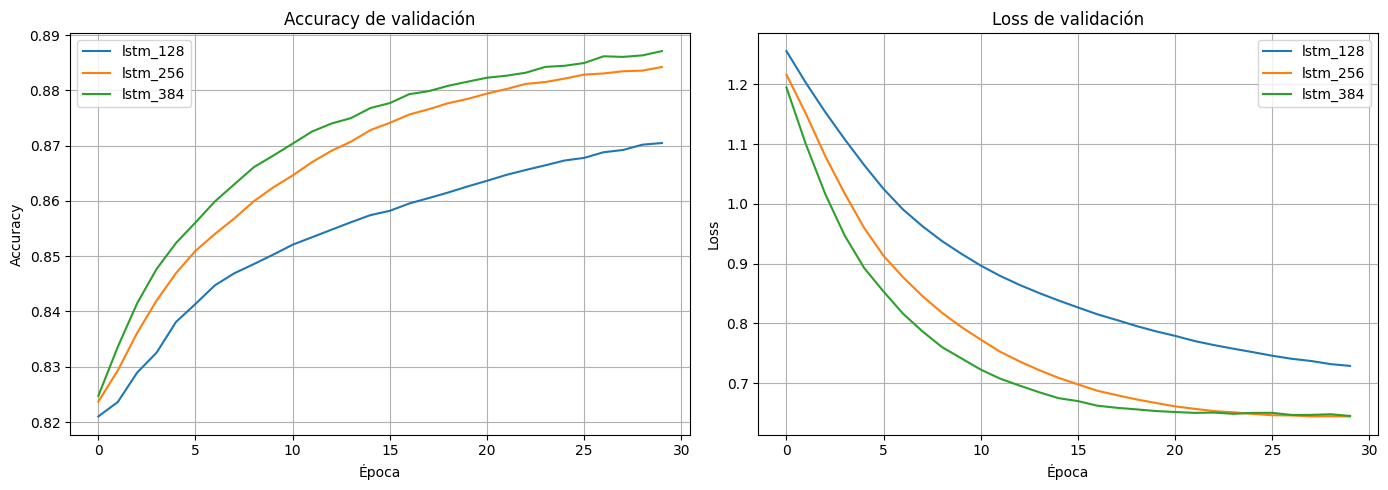

In [29]:


import os
import json
import matplotlib.pyplot as plt

carpeta_base = DIR_RESULTADOS
configuraciones = ["lstm_128", "lstm_256", "lstm_384"]

historiales = {}

for carpeta in configuraciones:
    ruta = os.path.join(carpeta_base, carpeta, "historial.json")

    if not os.path.exists(ruta):
        print(f"No se encontró: {ruta}")
        continue

    with open(ruta, "r", encoding="utf-8") as f:
        historiales[carpeta] = json.load(f)

# Gráficas comparativas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nombre, hist in historiales.items():
    # Accuracy de validación
    clave_acc = next(
        (k for k in ["val_accuracy", "val_weighted_accuracy"]
         if k in hist),
        None
    )

    if clave_acc:
        axes[0].plot(hist[clave_acc], label=nombre)

    # Loss de validación
    if "val_loss" in hist:
        axes[1].plot(hist["val_loss"], label=nombre)

axes[0].set_title("Accuracy de validación")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Loss de validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()




#Inferencia Modelo Seq2Seq

In [27]:
def build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer, n_units):
    """Modelo de encoder que solo devuelve los estados."""
    enc_emb = enc_emb_layer(enc_inputs)                    # reutiliza pesos entrenados
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return Model(enc_inputs, [state_h, state_c])


def build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units):
    """Modelo de decoder paso a paso (un token por vez)."""
    dec_input_single = Input(shape=(1,), name='dec_input_single')
    dec_state_h_in   = Input(shape=(n_units,), name='dec_state_h')
    dec_state_c_in   = Input(shape=(n_units,), name='dec_state_c')

    dec_emb_single = dec_emb_layer(dec_input_single)      # reutiliza pesos entrenados
    dec_out, h_out, c_out = dec_lstm_layer(
        dec_emb_single,
        initial_state=[dec_state_h_in, dec_state_c_in]
    )
    dec_out = dec_dense_layer(dec_out)

    return Model(
        [dec_input_single, dec_state_h_in, dec_state_c_in],
        [dec_out, h_out, c_out]
    )

In [28]:
encoder_model = build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer, n_units)
decoder_model = build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units)

Inferencia de greedy

In [30]:
idx2word_input  = {v: k for k, v in word2idx_inputs.items()}
idx2word_target = {v: k for k, v in word2idx_outputs.items()}

# Definimos la función de traducción adaptada a los modelos entrenados

In [42]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def translate_sentence(input_seq, encoder_model, decoder_model):
    h, c = encoder_model.predict(input_seq, verbose=0)

    target_seq = np.zeros((1, 1), dtype=np.int32)
    target_seq[0, 0] = word2idx_outputs["<sos>"]
    eos = word2idx_outputs["<eos>"]

    output_sentence = []

    for _ in range(max_out_len):
        output_tokens, h, c = decoder_model.predict(
            [target_seq, h, c],
            verbose=0
        )

        idx = int(np.argmax(output_tokens[0, 0, :]))

        if idx == eos:
            break

        if idx > 0:
            output_sentence.append(idx2word_target[idx])

        target_seq[0, 0] = idx

    return " ".join(output_sentence)


def translate(text, encoder_model, decoder_model):
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_input_len)
    return translate_sentence(seq, encoder_model, decoder_model)

In [35]:
modelos_cargados = {}

for unidades in [128, 256, 384]:
    ruta = os.path.join(
        DIR_RESULTADOS,
        f"lstm_{unidades}",
        "modelo_final.keras"
    )

    if os.path.exists(ruta):
        modelos_cargados[unidades] = tf.keras.models.load_model(
            ruta,
            compile=False
        )
        print(f"Modelo {unidades} cargado correctamente.")
    else:
        print(f"No se encontró el modelo: {ruta}")

Modelo 128 cargado correctamente.
Modelo 256 cargado correctamente.
Modelo 384 cargado correctamente.


**Preparando la inferencia**

In [43]:

# Mostrar las variables relacionadas con modelos y capas
for nombre in [
    "modelos",
    "inferencias",
    "encoder_model",
    "decoder_model",
    "model",
    "historiales"
]:
    print(f"{nombre}: {'Existe' if nombre in globals() else 'No existe'}")

# Buscar variables que puedan contener modelos Keras
for nombre, valor in list(globals().items()):
    if nombre.startswith("_"):
        continue
    if hasattr(valor, "layers") and hasattr(valor, "predict"):
        print(f"Modelo encontrado: {nombre}")

modelos: No existe
inferencias: Existe
encoder_model: Existe
decoder_model: Existe
model: No existe
historiales: Existe
Modelo encontrado: Model
Modelo encontrado: encoder_model
Modelo encontrado: decoder_model
Modelo encontrado: valor
Modelo encontrado: modelo
Modelo encontrado: encoder_inf
Modelo encontrado: decoder_inf


In [44]:

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input

inferencias = {}

for unidades, modelo in modelos_cargados.items():

    # Recuperar las capas entrenadas por nombre
    enc_inputs = modelo.get_layer("encoder_inputs")
    enc_emb_layer = modelo.get_layer("encoder_embedding")
    enc_lstm_layer = modelo.get_layer("encoder_lstm")

    dec_emb_layer = modelo.get_layer("decoder_embedding")
    dec_lstm_layer = modelo.get_layer("decoder_lstm")
    dec_dense_layer = modelo.get_layer("decoder_dense")

    # Encoder de inferencia: obtiene los estados finales
    encoder_inf_input = Input(shape=(max_input_len,), name=f"enc_inf_{unidades}")
    enc_emb = enc_emb_layer(encoder_inf_input)
    _, state_h, state_c = enc_lstm_layer(enc_emb)

    encoder_inf = Model(
        encoder_inf_input,
        [state_h, state_c],
        name=f"encoder_inference_{unidades}"
    )

    # Decoder de inferencia: genera un token por paso
    dec_input_single = Input(shape=(1,), dtype="int32")
    state_h_in = Input(shape=(unidades,))
    state_c_in = Input(shape=(unidades,))

    dec_emb = dec_emb_layer(dec_input_single)

    dec_out, h_out, c_out = dec_lstm_layer(
        dec_emb,
        initial_state=[state_h_in, state_c_in]
    )

    dec_probs = dec_dense_layer(dec_out)

    decoder_inf = Model(
        [dec_input_single, state_h_in, state_c_in],
        [dec_probs, h_out, c_out],
        name=f"decoder_inference_{unidades}"
    )

    inferencias[unidades] = (encoder_inf, decoder_inf)

print("Inferencias creadas:", list(inferencias.keys()))

Inferencias creadas: [128, 256, 384]


In [46]:
frases_prueba = [
    "How are you?",
    "I love you.",
    "My mother says hi.",
    "Where is the train station?",
    "I love learning languages."
]

for unidades in [128, 256, 384]:
    encoder_inf, decoder_inf = inferencias[unidades]

    print(f"\n{'=' * 55}")
    print(f"MODELO LSTM: {unidades} unidades")
    print("=" * 55)

    for frase in frases_prueba:
        traduccion = translate(frase, encoder_inf, decoder_inf)

        print(f"Inglés:     {frase}")
        print(f"Español:    {traduccion}\n")


MODELO LSTM: 128 unidades
Inglés:     How are you?
Español:    qué estás

Inglés:     I love you.
Español:    te gusta

Inglés:     My mother says hi.
Español:    mi padre está a casa

Inglés:     Where is the train station?
Español:    dónde está el tren

Inglés:     I love learning languages.
Español:    me gusta francés


MODELO LSTM: 256 unidades
Inglés:     How are you?
Español:    qué estás pensando

Inglés:     I love you.
Español:    te amo

Inglés:     My mother says hi.
Español:    mi hermana es feliz

Inglés:     Where is the train station?
Español:    dónde está el tren

Inglés:     I love learning languages.
Español:    conozco a los lenguas extranjeras


MODELO LSTM: 384 unidades
Inglés:     How are you?
Español:    qué estás bien

Inglés:     I love you.
Español:    te amo

Inglés:     My mother says hi.
Español:    mi madre le dijo a tom

Inglés:     Where is the train station?
Español:    dónde está el tren de tren

Inglés:     I love learning languages.
Español:    m

#Conclusiones finales acerca del experimento

Para realizar el traductor tomo como referencia el modelo de traducción brindado en la notebook de ejemplo. El objetivo fue analizar cómo distintas decisiones de diseño, particularmente el tamaño del conjunto de entrenamiento, la longitud de las secuencias y la cantidad de unidades recurrentes, influyen en el desempeño del modelo.

## Ampliación del conjunto de datos y longitud de las secuencias

Una de las modificaciones realizadas respecto de la configuración original fue ampliar el conjunto de datos de entrenamiento a 30.000 pares de oraciones y aumentar las longitudes máximas de las secuencias a 30 tokens para la entrada y 32 tokens para la salida.

Esta modificación permitió trabajar con un conjunto más amplio de ejemplos y contemplar oraciones de mayor longitud. Disponer de más pares de traducción puede favorecer el aprendizaje de relaciones entre palabras y estructuras lingüísticas, mientras que ampliar las secuencias permite representar frases que quedarían truncadas con límites más pequeños.

Sin embargo, aumentar la cantidad de datos y la longitud de las secuencias también incrementa los requerimientos de memoria y procesamiento. Además, una mayor cantidad de ejemplos no garantiza por sí sola una mejora en la calidad de las traducciones: el resultado depende también de la diversidad del corpus, de su calidad y de la capacidad de generalización del modelo.

## Comparación de arquitecturas LSTM

Se evaluaron tres configuraciones con diferentes cantidades de unidades recurrentes: 128, 256 y 384. El propósito fue estudiar cómo la capacidad de la red afecta el aprendizaje de las relaciones entre las oraciones de origen y destino.

De acuerdo con las curvas de validación observadas, la exactitud aumentó aproximadamente del 87,3 % para 128 unidades al 88,4 % para 256 unidades y al 88,8 % para 384 unidades. Estos valores son estimaciones visuales de la gráfica y deben reemplazarse por los valores exactos registrados durante el entrenamiento antes de presentar el informe definitivo.

Los resultados sugieren que aumentar la cantidad de unidades recurrentes produjo una mejora en la exactitud de validación. No obstante, el incremento entre las configuraciones de 256 y 384 unidades fue relativamente pequeño en comparación con el aumento de capacidad computacional requerido.

Por lo tanto, la configuración con 384 unidades presentó el mejor resultado aproximado en la métrica observada, mientras que la configuración con 256 unidades podría representar un compromiso razonable entre desempeño y costo computacional. Para determinar cuál resulta más conveniente, es necesario considerar también el tiempo de entrenamiento, la pérdida de validación y la calidad de las traducciones generadas.

## Análisis de las traducciones generadas

La generación de traducciones permitió observar el comportamiento de los modelos sobre frases que no se introducen necesariamente de la misma forma durante el entrenamiento. Este análisis cualitativo complementa las métricas numéricas, ya que una mayor exactitud durante la validación no implica necesariamente que las oraciones producidas sean gramaticalmente correctas, naturales o semánticamente equivalentes al texto original.

Al comparar las salidas de los tres modelos, resulta importante observar si conservan el significado de la oración, respetan el orden de las palabras, utilizan vocabulario adecuado y producen frases completas. También deben identificarse posibles omisiones, repeticiones, errores gramaticales o traducciones que resulten poco naturales.

Las traducciones generadas constituyen, por tanto, una evidencia complementaria para evaluar las diferencias entre las configuraciones. La selección del mejor modelo no debería basarse exclusivamente en la exactitud, sino también en la calidad lingüística de sus resultados.

## Consideraciones sobre la arquitectura y la inferencia

La arquitectura implementada utiliza un encoder que representa la oración de entrada mediante estados internos y un decoder que genera la secuencia de salida de manera autoregresiva, es decir, prediciendo un token por paso y utilizando el resultado anterior para producir el siguiente.

Para realizar la inferencia se construyeron modelos específicos a partir de las capas ya entrenadas. Estos modelos reutilizan los pesos aprendidos durante el entrenamiento y permiten ejecutar el proceso de traducción paso a paso, sin necesidad de volver a entrenar la red.

Esta separación entre entrenamiento e inferencia facilita la evaluación de distintas configuraciones y permite utilizar las redes entrenadas para generar traducciones de nuevas oraciones.

# Análisis de las gráficas

Las gráficas muestran una tendencia clara: al aumentar la cantidad de unidades LSTM de 128 a 256 y 384, mejora el desempeño durante la validación, aunque las ganancias disminuyen entre las dos configuraciones más grandes. Además, la pérdida de validación desciende de manera sostenida en los tres modelos.

**LSTM de 128 unidades**

La exactitud aumenta aproximadamente del 82,1 % al 87,1 %. El modelo aprende progresivamente, pero obtiene el menor desempeño de las tres configuraciones.

**LSTM de 256 unidades**

La exactitud alcanza aproximadamente el 88,4 %. Presenta una mejora clara respecto del modelo de 128 unidades, lo que sugiere que una mayor capacidad recurrente favorece el aprendizaje de las relaciones entre las secuencias en inglés y español.

**LSTM de 384 unidades**

Obtiene la mayor exactitud, aproximadamente el 88,7 %. Supera a la configuración de 256 unidades, aunque la diferencia final es pequeña.

**Conclusión**
El modelo de 384 unidades logra el mejor resultado de validación según esta métrica. Sin embargo, la mejora adicional respecto del modelo de 256 unidades es modesta, por lo que hay que considerar también el costo computacional.
